# Mouse E15.5 brain: Fig. 2

The saved joint embedding leads to the fixed spatial partition displayed in **Fig. 2a**. Follow the barcode alignment from embedding to tissue coordinates and final labels.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/01_Mouse_E15_5/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "01_Mouse_E15_5"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


Matplotlib is building the font cache; this may take a moment.


## 1. Load the saved representation and partition

`03_embeddings/MELON.csv` stores the joint representation. `04_clusters/final_clusters.csv` stores the final labels, tissue coordinates and reference annotations. Alignment uses barcode values, not CSV row position.

In [2]:
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
embedding = align_embedding(embedding, labels)
assert len(labels) == 1949
display(pd.DataFrame({"spots": [len(labels)], "embedding_dimensions": [embedding.shape[1]],
                       "MELON_domains": [labels.MELON.nunique()]}))

,spots,embedding_dimensions,MELON_domains
0,1949,128,12


## 2. Place the fixed labels on the tissue — Fig. 2a

Each dot is one saved spot. The RNA-only, ATAC-only and MELON columns are existing partitions. The notebook uses categorical colors for inspection; the manuscript montage below retains its original display-color matching.

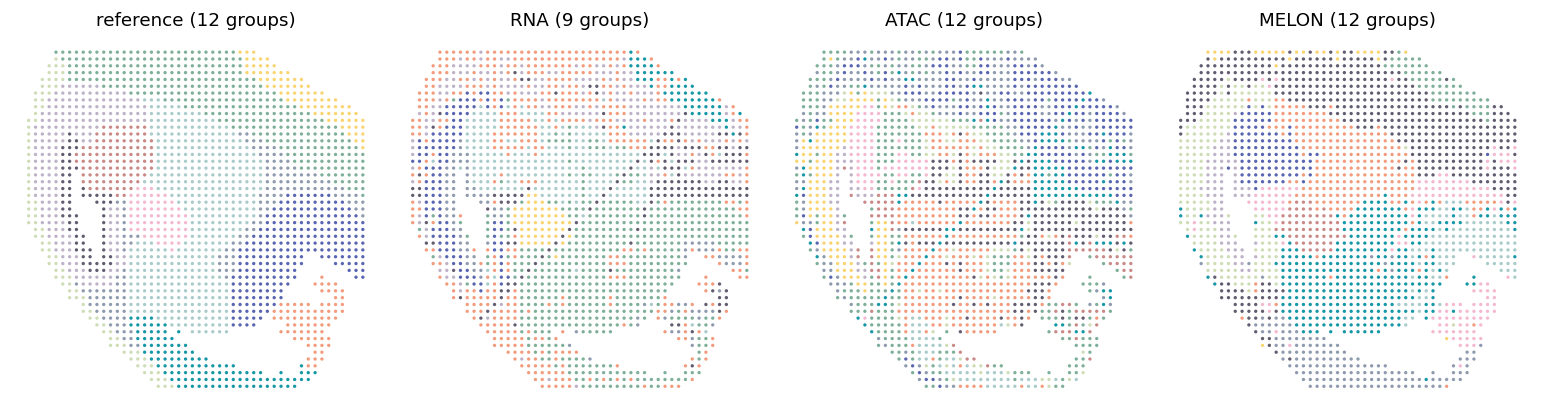

In [3]:
show(spatial_panels(labels, ["reference", "RNA", "ATAC", "MELON"], ncols=4))

## 3. Read the method-comparison columns

The comparison panels use the same coordinates and barcode cohort. SCIGMA is read from the saved final column, not reclustered from its embedding. The archive also retains a `totalvi` column; it is not included in the seven-method main comparison.

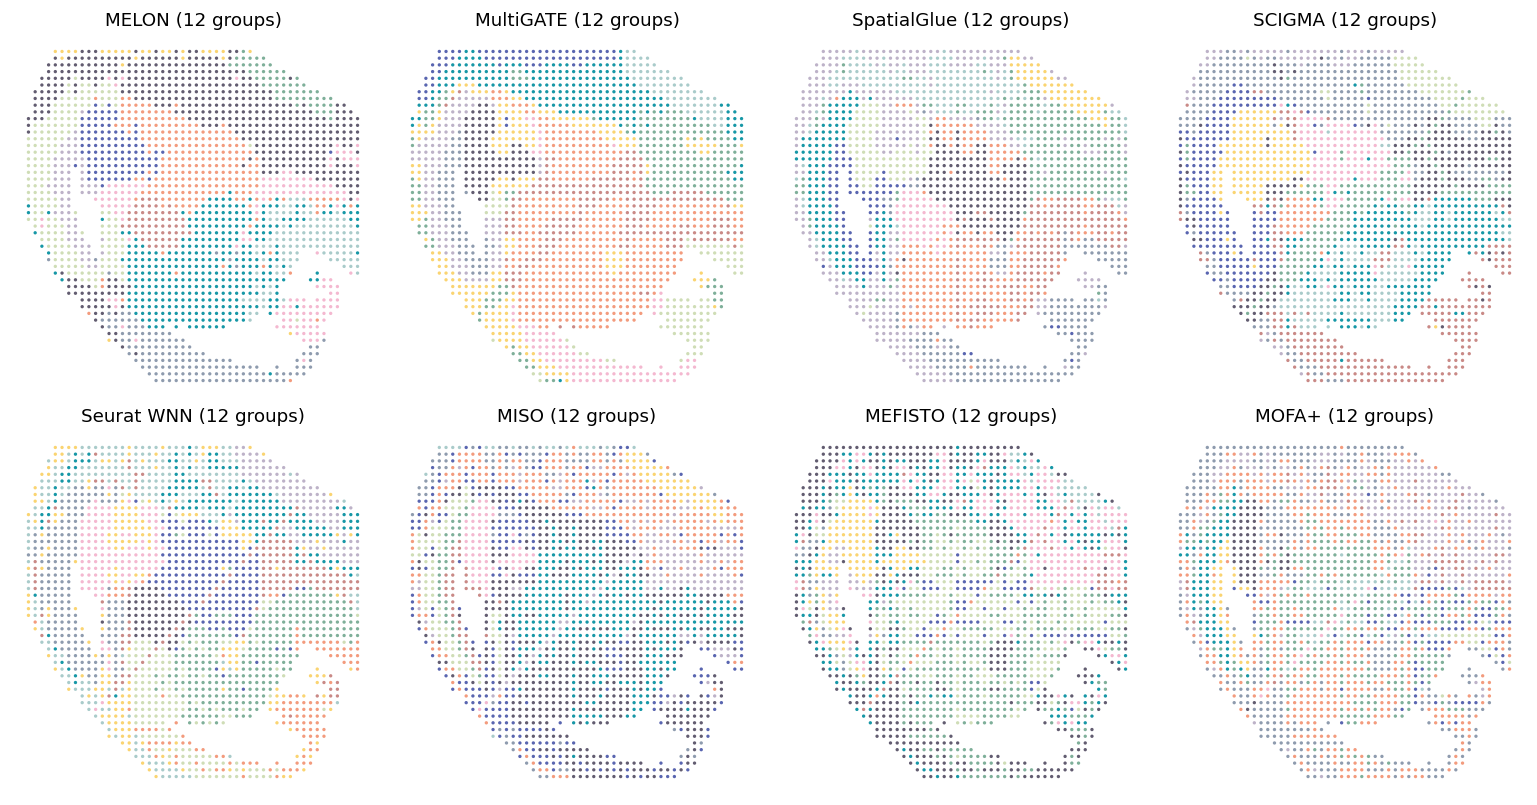

In [4]:
show(spatial_panels(labels, ["MELON", "MultiGATE", "SpatialGlue", "SCIGMA",
                            "Seurat WNN", "MISO", "MEFISTO", "MOFA+"], ncols=4))

## Corresponding manuscript figure

Panel **a** uses the saved spatial partitions above. Panels **b-c** add benchmark and region-level evaluation; **d-f** add expression, enrichment and latent/spatial summaries; **g-h** use external link support and decoder-derived pair activity.

![Manuscript Figure 2](../figures/paper_figure_2.png)

*Original manuscript figure, supplied PDF dated 2026-11-03. The notebook plots above are views of the saved data, not a replacement for this assembled figure.*

## Panel sources

| Panels | Source in this archive |
| --- | --- |
| 2a | `04_clusters/final_clusters.csv`, `01_source_data/tissue_reference.jpg` |
| 2b-c | Labels and references are present; the final benchmark/region-summary tables are separate |
| 2d-f | RNA source and embedding are present; the final expression/enrichment/t-SNE/network display tables are separate |
| 2g-h | Decoder, pair activity and scHiCAR/Brain2023 reference outputs are outside this archive |

The 32,285-gene original RNA matrix and the 2,144-gene modeling input are distinct. The archived run records seed 42, 100 epochs, batch size 2048 and spatial k = 16. See the separate [Fig. 5 walkthrough](../robustness/paper_figures.ipynb) for the saved sensitivity results.